In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import random
from collections import Counter
import io
from contextlib import redirect_stdout

In [ ]:
A = "A"
T = "T"
G = "G"
C = "C"

bases = [A, T, G, C]
complement = {A: T, T: A, G: C, C: G}
m_prob = 0.08

def replication_mut(adn,m_prob):
    adn_replique = []
    for base in adn:
      if random.random() < m_prob:
        adn_replique.append(random.choice([b for b in bases if b != base]))
      else:
            adn_replique.append(base)
    return adn_replique

valeur_cou = {A: 3, T: 1, G: 4, C: 0}

def score_eat(adn):
    allele = adn[0:4]
    score = sum(valeur_cou[base] for base in allele)
    return score

valeur_life = {A: 3, T: 3, G: 2, C: 4}

def score_life(adn):
    allele = adn[4:8]
    score = sum(valeur_life[base] for base in allele)
    return score

def reproduction(g1, g2):
    if g1.sexe == g2.sexe:
        return None
    a1 = replication_mut(g1.adn, m_prob)
    a2 = replication_mut(g2.adn, m_prob)
    gene_cou = random.choice([a1[0:4], a2[0:4]])
    gene_vie = random.choice([a1[4:8], a2[4:8]])
    return gene_cou + gene_vie


sexe = ["male", "female"]
class Girafe:
    def __init__(self, adn, sexe):
        self.adn = adn
        self.sexe = sexe
        self.score_cou = score_eat(adn)
        self.score_vie = score_life(adn)
        self.age = 0
        self.vivant = True
        self.cooldown = 0

    def vieillir(self, affame=False):
        self.age += 2 if affame else 1
        if self.cooldown > 0:
            self.cooldown -= 1
        if self.age >= self.score_vie:
            self.vivant = False

class environnement:
  def __init__(self, high):
    self.high_food = high
  def girafe_mange(self, girafe):
    return girafe.score_cou >= self.high_food

AGE_MIN = 4
INTERVALLE_REPRO = 3

def trouver_partenaire(girafe, population):
    candidats = [g for g in population
                 if g.vivant and g.sexe != girafe.sexe and g.age >= AGE_MIN]
    return random.choice(candidats) if candidats else None

In [ ]:

score_vie_stat = []
adn_stat = []
sexe_stat = []

def simulation(population, tour, environnement, prob_repro):
  for a in range(tour):
    newborn = []
    for girafe in population:
      if not girafe.vivant:
        continue
      girafe.vieillir(affame=not environnement.girafe_mange(girafe))
      if not girafe.vivant:
        continue
      adn_stat.append(girafe.adn)
      sexe_stat.append(girafe.sexe)
      score_vie_stat.append(girafe.score_vie)
      if girafe.sexe == "female" and girafe.age >= AGE_MIN and girafe.cooldown == 0 and random.random() < prob_repro:
         partenaire = trouver_partenaire(girafe, population)
         if partenaire is not None:
            enfant_adn = reproduction(girafe, partenaire)
            if enfant_adn is not None:
                enfant_sexe = random.choice(sexe)
                newborn.append(Girafe(enfant_adn, enfant_sexe))
                girafe.cooldown = INTERVALLE_REPRO
    population = population + newborn
    population = [g for g in population if g.vivant]
    print(f"Tour {a} : {len(population)} girafes vivantes")
  return population


In [ ]:
girafe1 = Girafe(adn = [A, C, A, G, C, C, T, G] , sexe = "male")
girafe2 = Girafe(adn = [T, G, A, G, T, C, G, A] , sexe = "female")
population1 = [girafe1, girafe2]
environnement1 = environnement(high = 5)

population1 = simulation(population1, 50, environnement1, 0.65)

Tour 0 : 2 girafes vivantes
Tour 1 : 2 girafes vivantes
Tour 2 : 2 girafes vivantes
Tour 3 : 3 girafes vivantes
Tour 4 : 3 girafes vivantes
Tour 5 : 3 girafes vivantes
Tour 6 : 3 girafes vivantes
Tour 7 : 3 girafes vivantes
Tour 8 : 3 girafes vivantes
Tour 9 : 4 girafes vivantes
Tour 10 : 4 girafes vivantes
Tour 11 : 3 girafes vivantes
Tour 12 : 2 girafes vivantes
Tour 13 : 2 girafes vivantes
Tour 14 : 3 girafes vivantes
Tour 15 : 3 girafes vivantes
Tour 16 : 2 girafes vivantes
Tour 17 : 2 girafes vivantes
Tour 18 : 2 girafes vivantes
Tour 19 : 3 girafes vivantes
Tour 20 : 3 girafes vivantes
Tour 21 : 2 girafes vivantes
Tour 22 : 2 girafes vivantes
Tour 23 : 2 girafes vivantes
Tour 24 : 2 girafes vivantes
Tour 25 : 3 girafes vivantes
Tour 26 : 3 girafes vivantes
Tour 27 : 2 girafes vivantes
Tour 28 : 2 girafes vivantes
Tour 29 : 2 girafes vivantes
Tour 30 : 2 girafes vivantes
Tour 31 : 2 girafes vivantes
Tour 32 : 1 girafes vivantes
Tour 33 : 1 girafes vivantes
Tour 34 : 1 girafes viva

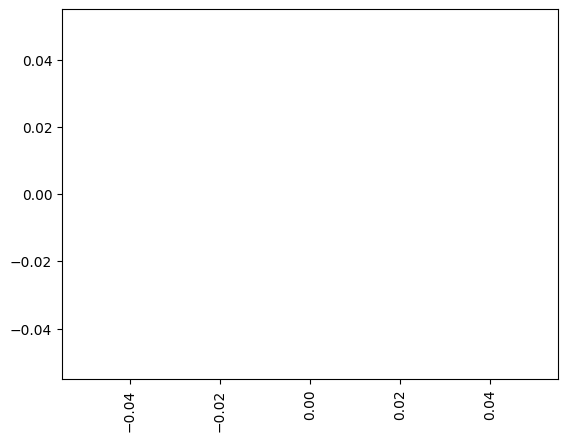

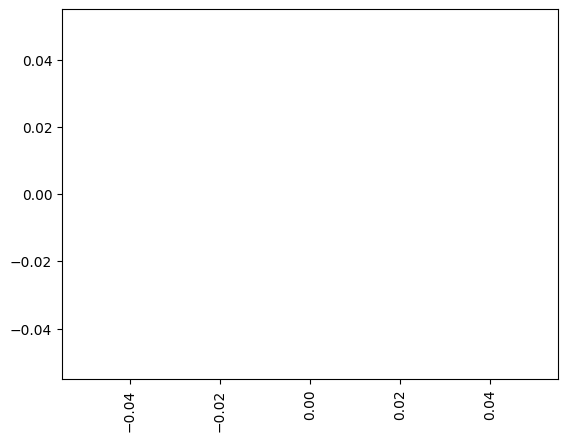

gene 1 : 
['A', 'C', 'A', 'G']
['T', 'G', 'A', 'G']
.
gene 2 :
['C', 'C', 'T', 'G']
['T', 'C', 'G', 'A']


In [ ]:
stockGene1 = []
stockGene2 = []

for girafe in population1:
  ad = girafe.adn.copy()
  gene1 = ad[0:4]
  gene2 = ad[4:8]
  stockGene1.append("".join(gene1))
  stockGene2.append("".join(gene2))

compte1 = Counter(stockGene1)
compte2 = Counter(stockGene2)

plt.bar(compte1.keys(), compte1.values())
plt.xlabel("")
plt.ylabel("")
plt.title("")
plt.xticks(rotation=90)
plt.show()

plt.bar(compte2.keys(), compte2.values())
plt.xlabel("")
plt.ylabel("")
plt.title("")
plt.xticks(rotation=90)
plt.show()

print("gene 1 : ")
print(girafe1.adn[0:4])
print(girafe2.adn[0:4])
print(".")
print("gene 2 :")
print(girafe1.adn[4:8])
print(girafe2.adn[4:8])

population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 20
population survivant sur 20: 19
population survivant sur 20: 18
population survivant sur 20: 16
population survivant sur 20: 12
population survivant sur 20: 10
population survivant sur 20: 8
population survivant sur 20: 8
population survivant sur 20: 8


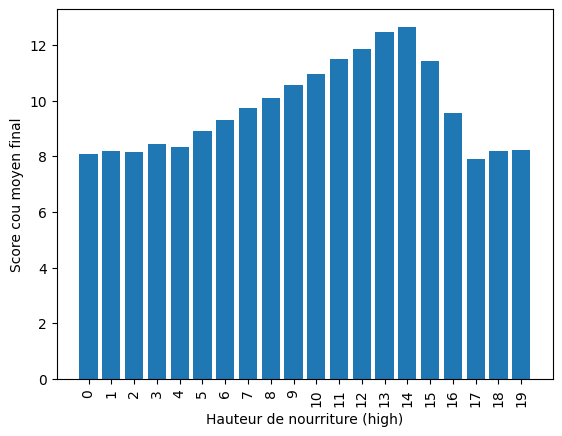

In [ ]:
def creer_girafe_aleatoire():
    adn = [random.choice(bases) for _ in range(8)]
    return Girafe(adn, random.choice(sexe))

results = {}

for high in range(20):
  mean_stock = []
  for i in range(20):
         pop = [creer_girafe_aleatoire() for _ in range(50)]
         env = environnement(high=high)
         with redirect_stdout(io.StringIO()):
            pop= simulation(pop, 50, env, 0.65)
         if len(pop) > 0:
          mean_stock.append(np.mean([g.score_cou for g in pop]))
  results[high] = mean_stock
  print("population survivant sur 20:", len(mean_stock))

x = list(results.keys())
y = [np.mean(m) if len(m) > 0 else 0 for m in results.values()]

plt.bar(x, y)
plt.xlabel("Hauteur de nourriture (high)")
plt.ylabel("Score cou moyen final")
plt.xticks(rotation=90)
plt.xticks(x)
plt.show()


Tour 0 : 50 girafes vivantes
Tour 1 : 59 girafes vivantes
Tour 2 : 63 girafes vivantes
Tour 3 : 73 girafes vivantes
Tour 4 : 78 girafes vivantes
Tour 5 : 68 girafes vivantes
Tour 6 : 70 girafes vivantes
Tour 7 : 73 girafes vivantes
Tour 8 : 74 girafes vivantes
Tour 9 : 74 girafes vivantes
Tour 10 : 75 girafes vivantes
Tour 11 : 73 girafes vivantes
Tour 12 : 72 girafes vivantes
Tour 13 : 71 girafes vivantes
Tour 14 : 77 girafes vivantes
Tour 15 : 75 girafes vivantes
Tour 16 : 69 girafes vivantes
Tour 17 : 71 girafes vivantes
Tour 18 : 74 girafes vivantes
Tour 19 : 72 girafes vivantes
Tour 20 : 73 girafes vivantes
Tour 21 : 71 girafes vivantes
Tour 22 : 67 girafes vivantes
Tour 23 : 70 girafes vivantes
Tour 24 : 71 girafes vivantes
Tour 25 : 64 girafes vivantes
Tour 26 : 64 girafes vivantes
Tour 27 : 67 girafes vivantes
Tour 28 : 68 girafes vivantes
Tour 29 : 62 girafes vivantes
Tour 30 : 61 girafes vivantes
Tour 31 : 61 girafes vivantes
Tour 32 : 61 girafes vivantes
Tour 33 : 65 girafes

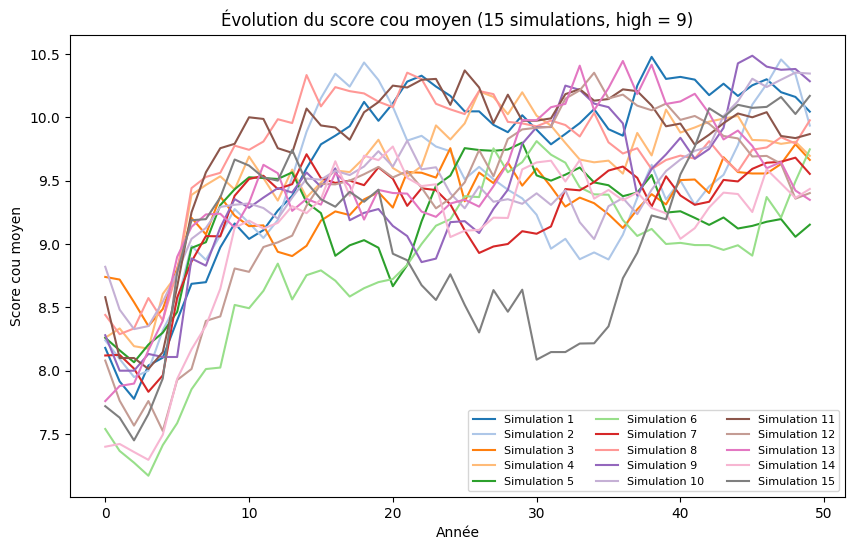

In [ ]:
def simulation_stat(population, tour, environnement, prob_repro):
  historique = []
  for a in range(tour):
    newborn = []
    for girafe in population:
      if not girafe.vivant:
        continue
      girafe.vieillir(affame=not environnement.girafe_mange(girafe))
      if not girafe.vivant:
        continue
      if girafe.sexe == "female" and girafe.age >= AGE_MIN and girafe.cooldown == 0 and random.random() < prob_repro:
         partenaire = trouver_partenaire(girafe, population)
         if partenaire is not None:
            enfant_adn = reproduction(girafe, partenaire)
            if enfant_adn is not None:
                enfant_sexe = random.choice(sexe)
                newborn.append(Girafe(enfant_adn, enfant_sexe))
                girafe.cooldown = INTERVALLE_REPRO
    population = population + newborn
    population = [g for g in population if g.vivant]
    historique.append({"tour": a, "n": len(population), "scores_cou": [g.score_cou for g in population], "genes": ["".join(g.adn[0:4]) for g in population], "scores_life": [g.score_vie for g in population],})
    print(f"Tour {a} : {len(population)} girafes vivantes")
  return population, historique

moyenne_graph = {}

for i in range(15):
  environnement_stat1 = environnement(high = 9)
  pop1_stat = [creer_girafe_aleatoire() for _ in range(50)]
  pop1_stat, historique1 = simulation_stat(pop1_stat, 50, environnement_stat1 , 0.65)
  moyennes = [np.mean(h["scores_cou"]) if h["n"] > 0 else np.nan for h in historique1]
  moyenne_graph[i] = moyennes


plt.figure(figsize=(10, 6))
cmap = plt.get_cmap("tab20")

for i, courbe in moyenne_graph.items():
    plt.plot(courbe, color=cmap(i), label=f"Simulation {i+1}")

plt.xlabel("Année")
plt.ylabel("Score cou moyen")
plt.title("Évolution du score cou moyen (15 simulations, high = 9)")
plt.legend(ncol=3, fontsize=8)
plt.show()


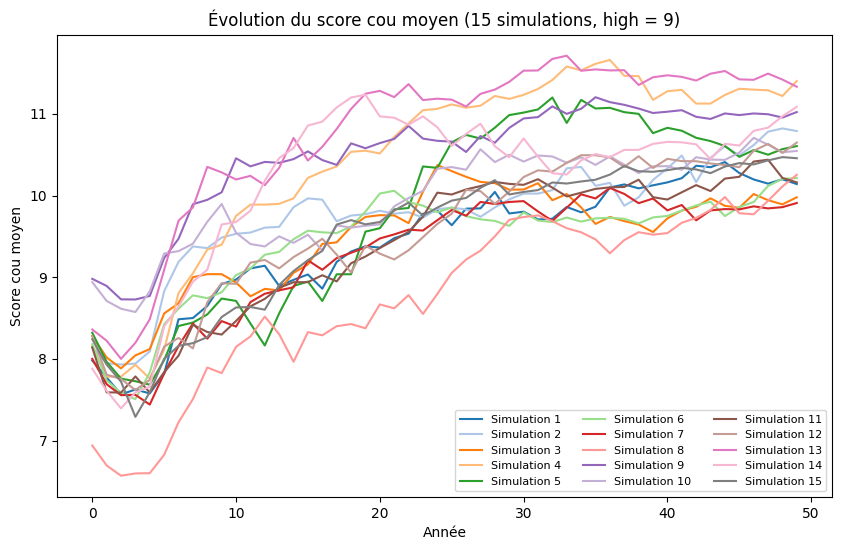

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(10, 6))
cmap = plt.get_cmap("tab20")

for i, courbe in moyenne_graph.items():
    plt.plot(courbe, color=cmap(i), label=f"Simulation {i+1}")

plt.xlabel("Année")
plt.ylabel("Score cou moyen")
plt.title("Évolution du score cou moyen (15 simulations, high = 9)")
plt.legend(ncol=3, fontsize=8)
plt.savefig("fig1_selection_cou.png", dpi=300)
plt.show()

from google.colab import files
files.download("fig1_selection_cou.png")

In [ ]:
mutations = [0, 0.001, 0.01, 0.05, 0.1, 0.3]
repetitions = 5
diversite = {}

for m in mutations:
    m_prob = m
    valeurs = []
    for r in range(repetitions):
        pop = [creer_girafe_aleatoire() for _ in range(50)]
        env = environnement(high=9)
        pop, hist = simulation_stat(pop, 50, env, 0.65)
        if len(pop) > 0:
            genes = {"".join(g.adn[0:4]) for g in pop}
            valeurs.append(len(genes))
    diversite[m] = valeurs
    moyennes = [np.mean(h["scores_cou"]) if h["m"] > 0 else np.nan for h in hist]

for m in mutations:
    m_prob = m
    valeurs = []
    for r in range(repetitions):
        pop = [creer_girafe_aleatoire() for _ in range(50)]
        env = environnement(high=0)
        pop, hist = simulation_stat(pop, 50, env, 0.65)
        if len(pop) > 0:
            genes = {"".join(g.adn[0:4]) for g in pop}
            valeurs.append(len(genes))
    diversite[m] = valeurs
    moyennes = [np.mean(h["scores_cou"]) if h["m"] > 0 else np.nan for h in hist]

Tour 0 : 50 girafes vivantes
Tour 1 : 59 girafes vivantes
Tour 2 : 64 girafes vivantes
Tour 3 : 71 girafes vivantes
Tour 4 : 73 girafes vivantes
Tour 5 : 60 girafes vivantes
Tour 6 : 51 girafes vivantes
Tour 7 : 52 girafes vivantes
Tour 8 : 52 girafes vivantes
Tour 9 : 51 girafes vivantes
Tour 10 : 52 girafes vivantes
Tour 11 : 52 girafes vivantes
Tour 12 : 51 girafes vivantes
Tour 13 : 57 girafes vivantes
Tour 14 : 60 girafes vivantes
Tour 15 : 63 girafes vivantes
Tour 16 : 64 girafes vivantes
Tour 17 : 68 girafes vivantes
Tour 18 : 68 girafes vivantes
Tour 19 : 68 girafes vivantes
Tour 20 : 70 girafes vivantes
Tour 21 : 74 girafes vivantes
Tour 22 : 74 girafes vivantes
Tour 23 : 76 girafes vivantes
Tour 24 : 82 girafes vivantes
Tour 25 : 82 girafes vivantes
Tour 26 : 73 girafes vivantes
Tour 27 : 76 girafes vivantes
Tour 28 : 80 girafes vivantes
Tour 29 : 79 girafes vivantes
Tour 30 : 77 girafes vivantes
Tour 31 : 83 girafes vivantes
Tour 32 : 83 girafes vivantes
Tour 33 : 81 girafes

KeyError: 'm'

Tour 0 : 50 girafes vivantes
Tour 1 : 50 girafes vivantes
Tour 2 : 50 girafes vivantes
Tour 3 : 68 girafes vivantes
Tour 4 : 77 girafes vivantes
Tour 5 : 78 girafes vivantes
Tour 6 : 94 girafes vivantes
Tour 7 : 107 girafes vivantes
Tour 8 : 119 girafes vivantes
Tour 9 : 127 girafes vivantes
Tour 10 : 127 girafes vivantes
Tour 11 : 135 girafes vivantes
Tour 12 : 124 girafes vivantes
Tour 13 : 128 girafes vivantes
Tour 14 : 133 girafes vivantes
Tour 15 : 145 girafes vivantes
Tour 16 : 144 girafes vivantes
Tour 17 : 146 girafes vivantes
Tour 18 : 151 girafes vivantes
Tour 19 : 153 girafes vivantes
Tour 20 : 158 girafes vivantes
Tour 21 : 163 girafes vivantes
Tour 22 : 165 girafes vivantes
Tour 23 : 173 girafes vivantes
Tour 24 : 176 girafes vivantes
Tour 25 : 184 girafes vivantes
Tour 26 : 191 girafes vivantes
Tour 27 : 192 girafes vivantes
Tour 28 : 204 girafes vivantes
Tour 29 : 210 girafes vivantes
Tour 30 : 218 girafes vivantes
Tour 31 : 224 girafes vivantes
Tour 32 : 232 girafes viv

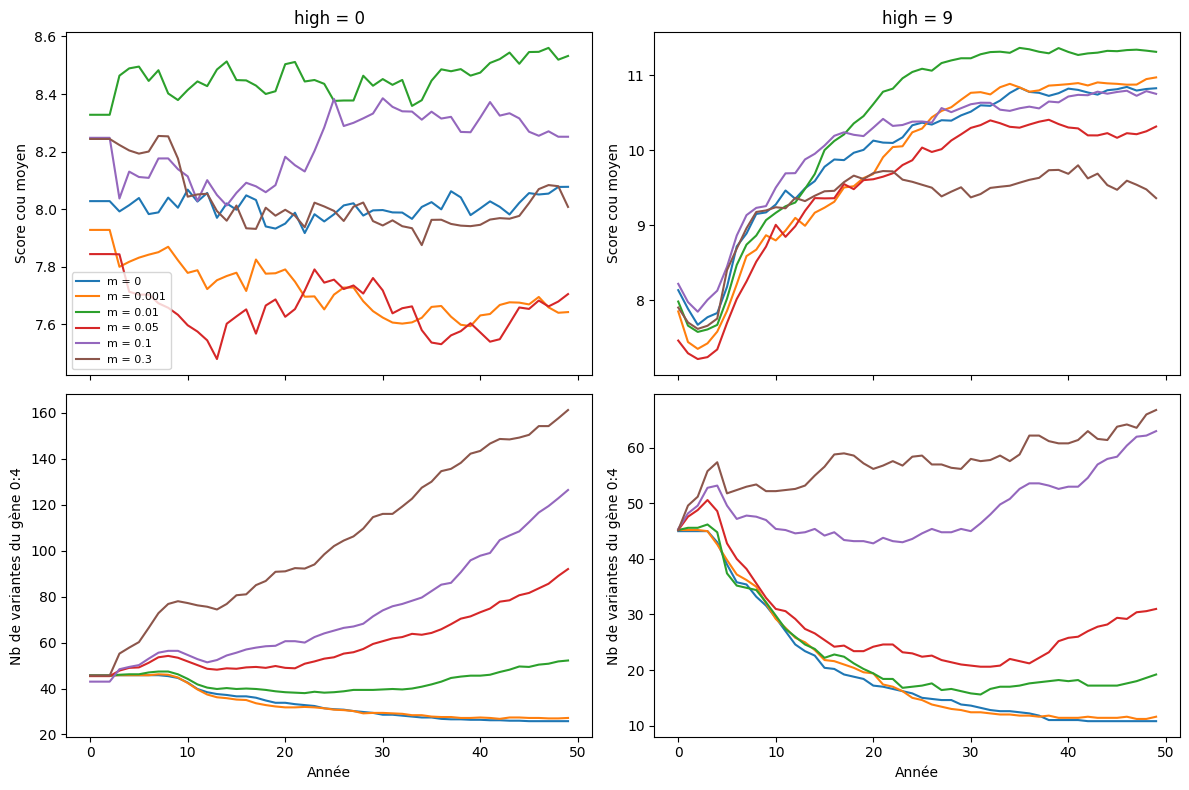

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def lancer(high, m, repetitions=5, tours=50):
    global m_prob
    m_prob = m
    scores, divs = [], []
    for r in range(repetitions):
        pop = [creer_girafe_aleatoire() for _ in range(50)]
        env = environnement(high=high)
        pop, hist = simulation_stat(pop, tours, env, 0.65)
        scores.append([np.mean(h["scores_cou"]) if h["n"] > 0 else np.nan for h in hist])
        divs.append([len(set(h["genes"])) if h["n"] > 0 else np.nan for h in hist])
    return np.nanmean(scores, axis=0), np.nanmean(divs, axis=0)


mutations = [0, 0.001, 0.01, 0.05, 0.1, 0.3]
resultats = {}
for high in [0, 9]:
    for m in mutations:
        resultats[(high, m)] = lancer(high, m)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for col, high in enumerate([0, 9]):
    for m in mutations:
        sc, dv = resultats[(high, m)]
        axes[0, col].plot(sc, label=f"m = {m}")
        axes[1, col].plot(dv, label=f"m = {m}")
    axes[0, col].set_title(f"high = {high}")
    axes[0, col].set_ylabel("Score cou moyen")
    axes[1, col].set_ylabel("Nb de variantes du gène 0:4")
    axes[1, col].set_xlabel("Année")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig2", dpi=300)
plt.show()
from google.colab import files
files.download("fig2.png")

In [ ]:
from google.colab import files
files.download("fig2.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tour 0 : 50 girafes vivantes
Tour 1 : 68 girafes vivantes
Tour 2 : 74 girafes vivantes
Tour 3 : 83 girafes vivantes
Tour 4 : 97 girafes vivantes
Tour 5 : 114 girafes vivantes
Tour 6 : 127 girafes vivantes
Tour 7 : 91 girafes vivantes
Tour 8 : 104 girafes vivantes
Tour 9 : 95 girafes vivantes
Tour 10 : 103 girafes vivantes
Tour 11 : 107 girafes vivantes
Tour 12 : 101 girafes vivantes
Tour 13 : 94 girafes vivantes
Tour 14 : 91 girafes vivantes
Tour 15 : 84 girafes vivantes
Tour 16 : 83 girafes vivantes
Tour 17 : 87 girafes vivantes
Tour 18 : 81 girafes vivantes
Tour 19 : 82 girafes vivantes
Tour 20 : 87 girafes vivantes
Tour 21 : 93 girafes vivantes
Tour 22 : 98 girafes vivantes
Tour 23 : 110 girafes vivantes
Tour 24 : 109 girafes vivantes
Tour 25 : 113 girafes vivantes
Tour 26 : 124 girafes vivantes
Tour 27 : 119 girafes vivantes
Tour 28 : 120 girafes vivantes
Tour 29 : 117 girafes vivantes
Tour 30 : 118 girafes vivantes
Tour 31 : 114 girafes vivantes
Tour 32 : 118 girafes vivantes
Tour

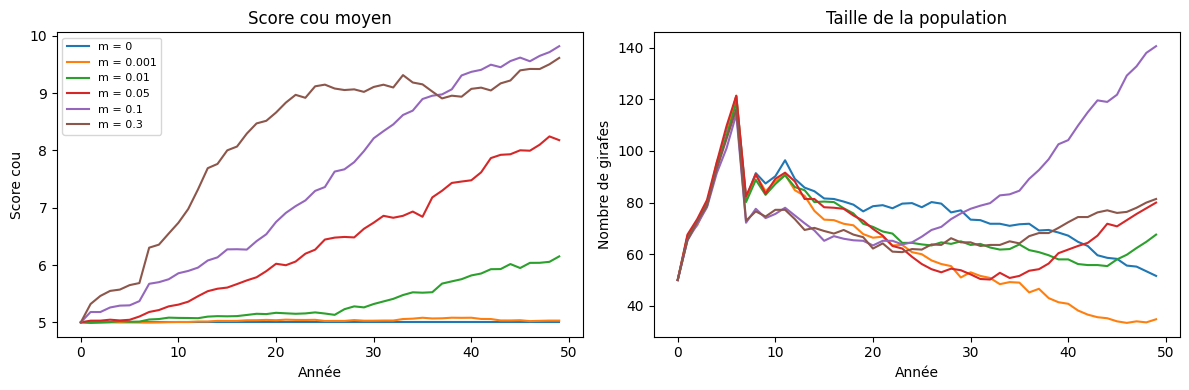

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def creer_clone1(i):
    adn = [A, T, T, C, C, C, C, C]
    return Girafe(adn.copy(), "male" if i % 2 == 0 else "female")

mutations = [0, 0.001, 0.01, 0.05, 0.1, 0.3]
repetitions = 5

res_cou = {}
res_pop = {}
survie = {}

for m in mutations:
    m_prob = m
    cou_reps, pop_reps = [], []
    for r in range(repetitions):
        pop4 = [creer_clone1(i) for i in range(50)]      # population neuve à chaque fois
        env4 = environnement(high=9)
        pop4, hist4 = simulation_stat(pop4, 50, env4, 0.65)
        cou_reps.append([np.mean(h["scores_cou"]) if h["n"] > 0 else np.nan for h in hist4])
        pop_reps.append([h["n"] for h in hist4])
    res_cou[m] = np.nanmean(cou_reps, axis=0)            # moyenne des répétitions, année par année
    res_pop[m] = np.mean(pop_reps, axis=0)
    survie[m] = sum(p[-1] > 0 for p in pop_reps)         # nb de populations encore vivantes à la fin

    print(f"m = {m} : {survie[m]}/{repetitions} populations survivantes")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m in mutations:
    axes[0].plot(res_cou[m], label=f"m = {m}")
    axes[1].plot(res_pop[m], label=f"m = {m}")
axes[0].set_title("Score cou moyen")
axes[0].set_ylabel("Score cou")
axes[1].set_title("Taille de la population")
axes[1].set_ylabel("Nombre de girafes")
for ax in axes:
    ax.set_xlabel("Année")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig3.png", dpi=300)
plt.show()

from google.colab import files
files.download("fig3.png")